## 1. Título y objetivo

Este análisis estudia la evolución de la carga eléctrica y los precios
en una serie temporal horaria. Se analizarán los patrones diarios,
las diferencias entre días laborables y fines de semana, y la relación
entre demanda, generación renovable y precio.

In [1]:
# Manipulación y análisis de datos
import numpy as np
import pandas as pd

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns

# Estadística
from scipy import stats

# Series temporales y modelos estadísticos
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller

In [2]:
# Configuración visual

sns.set_theme(style="whitegrid")

plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

## 2. Importaciones

In [3]:
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("Importaciones realizadas correctamente")

NumPy: 2.4.6
pandas: 3.0.3
Importaciones realizadas correctamente


In [4]:
energy_raw = pd.read_csv("energy_dataset(kaggle).csv")

In [5]:
print("Filas:", energy_raw.shape[0])
print("Columnas:", energy_raw.shape[1])

Filas: 35064
Columnas: 29


## 3. Carga de datos

In [6]:
energy_raw = pd.read_csv("energy_dataset(kaggle).csv")

print("Dimensiones:", energy_raw.shape)
print("\nPrimeras filas:")
display(energy_raw.head())

print("\nTipos de datos:")
display(energy_raw.dtypes)

print("\nInformación general:")
energy_raw.info()

Dimensiones: (35064, 29)

Primeras filas:


,time,generation biomass,generation fossil brown coal/lignite,generation fossil coal-derived gas,generation fossil gas,generation fossil hard coal,generation fossil oil,generation fossil oil shale,generation fossil peat,generation geothermal,...,generation waste,generation wind offshore,generation wind onshore,forecast solar day ahead,forecast wind offshore eday ahead,forecast wind onshore day ahead,total load forecast,total load actual,price day ahead,price actual
0,2015-01-01 00:00:00+01:00,447.0,329.0,0.0,4844.0,4821.0,162.0,0.0,0.0,0.0,...,196.0,0.0,6378.0,17.0,NaN,6436.0,26118.0,25385.0,50.10,65.41
1,2015-01-01 01:00:00+01:00,449.0,328.0,0.0,5196.0,4755.0,158.0,0.0,0.0,0.0,...,195.0,0.0,5890.0,16.0,NaN,5856.0,24934.0,24382.0,48.10,64.92
2,2015-01-01 02:00:00+01:00,448.0,323.0,0.0,4857.0,4581.0,157.0,0.0,0.0,0.0,...,196.0,0.0,5461.0,8.0,NaN,5454.0,23515.0,22734.0,47.33,64.48
3,2015-01-01 03:00:00+01:00,438.0,254.0,0.0,4314.0,4131.0,160.0,0.0,0.0,0.0,...,191.0,0.0,5238.0,2.0,NaN,5151.0,22642.0,21286.0,42.27,59.32
4,2015-01-01 04:00:00+01:00,428.0,187.0,0.0,4130.0,3840.0,156.0,0.0,0.0,0.0,...,189.0,0.0,4935.0,9.0,NaN,4861.0,21785.0,20264.0,38.41,56.04



Tipos de datos:


time                                               str
generation biomass                             float64
generation fossil brown coal/lignite           float64
generation fossil coal-derived gas             float64
generation fossil gas                          float64
generation fossil hard coal                    float64
generation fossil oil                          float64
generation fossil oil shale                    float64
generation fossil peat                         float64
generation geothermal                          float64
generation hydro pumped storage aggregated     float64
generation hydro pumped storage consumption    float64
generation hydro run-of-river and poundage     float64
generation hydro water reservoir               float64
generation marine                              float64
generation nuclear                             float64
generation other                               float64
generation other renewable                     float64
generation


Información general:
<class 'pandas.DataFrame'>
RangeIndex: 35064 entries, 0 to 35063
Data columns (total 29 columns):
 #   Column                                       Non-Null Count  Dtype  
---  ------                                       --------------  -----  
 0   time                                         35064 non-null  str    
 1   generation biomass                           35045 non-null  float64
 2   generation fossil brown coal/lignite         35046 non-null  float64
 3   generation fossil coal-derived gas           35046 non-null  float64
 4   generation fossil gas                        35046 non-null  float64
 5   generation fossil hard coal                  35046 non-null  float64
 6   generation fossil oil                        35045 non-null  float64
 7   generation fossil oil shale                  35046 non-null  float64
 8   generation fossil peat                       35046 non-null  float64
 9   generation geothermal                        35046 non-null  

## 4. Selección de columnas

In [7]:
columnas_analisis = [
    "time",
    "total load actual",
    "total load forecast",
    "price actual",
    "price day ahead",
    "generation solar",
    "generation wind onshore",
    "generation wind offshore",
    "generation hydro water reservoir"
]

energy = energy_raw[columnas_analisis].copy()

print("Dimensiones:", energy.shape)
display(energy.head())

Dimensiones: (35064, 9)


,time,total load actual,total load forecast,price actual,price day ahead,generation solar,generation wind onshore,generation wind offshore,generation hydro water reservoir
0,2015-01-01 00:00:00+01:00,25385.0,26118.0,65.41,50.10,49.0,6378.0,0.0,1899.0
1,2015-01-01 01:00:00+01:00,24382.0,24934.0,64.92,48.10,50.0,5890.0,0.0,1658.0
2,2015-01-01 02:00:00+01:00,22734.0,23515.0,64.48,47.33,50.0,5461.0,0.0,1371.0
3,2015-01-01 03:00:00+01:00,21286.0,22642.0,59.32,42.27,50.0,5238.0,0.0,779.0
4,2015-01-01 04:00:00+01:00,20264.0,21785.0,56.04,38.41,42.0,4935.0,0.0,720.0


## 5. Índice temporal

In [8]:
energy["time"] = pd.to_datetime(
    energy["time"],
    utc=True
)

energy = (
    energy
    .sort_values("time")
    .set_index("time")
)

frecuencia = energy.index.to_series().diff().median()

print("Tipo de índice:", type(energy.index))
print("Inicio:", energy.index.min())
print("Fin:", energy.index.max())
print("Índice ordenado:", energy.index.is_monotonic_increasing)
print("Índice único:", energy.index.is_unique)
print("Frecuencia aproximada:", frecuencia)

Tipo de índice: <class 'pandas.DatetimeIndex'>
Inicio: 2014-12-31 23:00:00+00:00
Fin: 2018-12-31 22:00:00+00:00
Índice ordenado: True
Índice único: True
Frecuencia aproximada: 0 days 01:00:00


In [9]:
energy_local = energy.copy()
energy_local.index = energy_local.index.tz_convert("Europe/Madrid")

## 6. Validación mínima

In [10]:
print("Dimensiones:", energy.shape)
print("Índice ordenado:", energy.index.is_monotonic_increasing)
print("Índice único:", energy.index.is_unique)
print("Filas duplicadas:", energy.duplicated().sum())
print("Frecuencia:", energy.index.to_series().diff().median())

print("\nValores nulos:")
display(energy.isna().sum())

print("\nTipos de datos:")
display(energy.dtypes)

Dimensiones: (35064, 8)
Índice ordenado: True
Índice único: True
Filas duplicadas: 0
Frecuencia: 0 days 01:00:00

Valores nulos:


total load actual                   36
total load forecast                  0
price actual                         0
price day ahead                      0
generation solar                    18
generation wind onshore             18
generation wind offshore            18
generation hydro water reservoir    18
dtype: int64


Tipos de datos:


total load actual                   float64
total load forecast                 float64
price actual                        float64
price day ahead                     float64
generation solar                    float64
generation wind onshore             float64
generation wind offshore            float64
generation hydro water reservoir    float64
dtype: object

## 7. Tratamiento de nulos

In [11]:
energy = energy_raw[columnas_analisis].copy()

energy["time"] = pd.to_datetime(
    energy["time"],
    utc=True
)

energy = (
    energy
    .sort_values("time")
    .set_index("time")
)

In [12]:
columnas_imputables = [
    "total load actual",
    "generation solar",
    "generation wind onshore",
    "generation wind offshore",
    "generation hydro water reservoir"
]

energy["any_imputation"] = (
    energy[columnas_imputables].isna().any(axis=1)
)

nulos_antes = energy[columnas_imputables].isna().sum()

energy[columnas_imputables] = (
    energy[columnas_imputables]
    .interpolate(method="time")
)

nulos_despues = energy[columnas_imputables].isna().sum()

print("Nulos antes:")
display(nulos_antes)

print("Nulos después:")
display(nulos_despues)

print(
    "Filas con al menos un valor imputado:",
    energy["any_imputation"].sum()
)

Nulos antes:


total load actual                   36
generation solar                    18
generation wind onshore             18
generation wind offshore            18
generation hydro water reservoir    18
dtype: int64

Nulos después:


total load actual                   0
generation solar                    0
generation wind onshore             0
generation wind offshore            0
generation hydro water reservoir    0
dtype: int64

Filas con al menos un valor imputado: 41


In [13]:
energy[columnas_imputables].isna().sum().sum()

np.int64(0)

## 8. Variables derivadas

In [14]:
# Variables temporales
energy["hour"] = energy.index.hour
energy["day_of_week"] = energy.index.dayofweek
energy["month"] = energy.index.month
energy["year"] = energy.index.year

# Tipo de día
energy["day_type"] = np.where(
    energy["day_of_week"] < 5,
    "Laborable",
    "Fin de semana"
)

# Generación renovable
columnas_renovables = [
    "generation solar",
    "generation wind onshore",
    "generation wind offshore",
    "generation hydro water reservoir"
]

energy["renewable_generation"] = (
    energy[columnas_renovables].sum(axis=1)
)

# Error de previsión
energy["load_forecast_error"] = (
    energy["total load actual"]
    - energy["total load forecast"]
)

energy["load_forecast_error_abs"] = (
    energy["load_forecast_error"].abs()
)

In [15]:
columnas_derivadas = [
    "hour",
    "day_of_week",
    "month",
    "year",
    "day_type",
    "renewable_generation",
    "load_forecast_error",
    "load_forecast_error_abs"
]

display(energy[columnas_derivadas].head())

,hour,day_of_week,month,year,day_type,renewable_generation,load_forecast_error,load_forecast_error_abs
time,,,,,,,,
2014-12-31 23:00:00+00:00,23,2,12,2014,Laborable,8326.0,-733.0,733.0
2015-01-01 00:00:00+00:00,0,3,1,2015,Laborable,7598.0,-552.0,552.0
2015-01-01 01:00:00+00:00,1,3,1,2015,Laborable,6882.0,-781.0,781.0
2015-01-01 02:00:00+00:00,2,3,1,2015,Laborable,6067.0,-1356.0,1356.0
2015-01-01 03:00:00+00:00,3,3,1,2015,Laborable,5697.0,-1521.0,1521.0


In [16]:
print("Hora mínima:", energy["hour"].min())
print("Hora máxima:", energy["hour"].max())
print(energy["day_type"].unique())

Hora mínima: 0
Hora máxima: 23
<ArrowStringArray>
['Laborable', 'Fin de semana']
Length: 2, dtype: str


## 9. Estadísticas descriptivas

In [17]:
variables_descriptivas = [
    "total load actual",
    "total load forecast",
    "price actual",
    "price day ahead",
    "renewable_generation",
    "load_forecast_error"
]

resumen = (
    energy[variables_descriptivas]
    .describe()
    .T
    .round(2)
)

resumen["rango"] = resumen["max"] - resumen["min"]
resumen["nulos"] = energy[variables_descriptivas].isna().sum()

display(resumen)

,count,mean,std,min,25%,50%,75%,max,rango,nulos
total load actual,35064.0,28698.28,4575.83,18041.00,24807.00,28902.00,32194.25,41015.00,22974.00,0
total load forecast,35064.0,28712.13,4594.10,18105.00,24793.75,28906.00,32263.25,41390.00,23285.00,0
price actual,35064.0,57.88,14.20,9.33,49.35,58.02,68.01,116.80,107.47,0
price day ahead,35064.0,49.87,14.62,2.06,41.49,50.52,60.53,101.99,99.93,0
renewable_generation,35064.0,9503.33,3879.91,0.00,6672.00,9121.50,11927.00,25270.00,25270.00,0
load_forecast_error,35064.0,-13.85,454.45,-13506.00,-245.00,-12.00,219.00,6244.00,19750.00,0


### Interpretación

La carga eléctrica real presenta una media de 28.698,28 y una mediana
de 28.902, con valores comprendidos entre 18.041 y 41.015. La carga
prevista presenta valores medios muy similares, aunque esta similitud
global debe complementarse con el análisis del error de previsión.

El precio real tiene una media de 57,88, superior a la media del precio
previsto, que es de 49,87. Esta diferencia sugiere que la previsión del
precio puede presentar un sesgo, que se analizará mediante una variable
de error específica.

La generación renovable tiene una media de 9.503,33 y una desviación
estándar de 3.879,91, lo que refleja una variabilidad considerable.

El error medio de previsión de la carga es de -13,85, cercano a cero,
pero su desviación estándar es de 454,55. Por tanto, la previsión no
presenta un sesgo medio importante, aunque su precisión varía según el
momento.

In [18]:
energy["price_forecast_error"] = (
    energy["price actual"]
    - energy["price day ahead"]
)

energy["price_forecast_error"].describe().round(2)

count    35064.00
mean         8.01
std         10.55
min        -61.04
25%          5.37
50%          7.41
75%         10.67
max         77.58
Name: price_forecast_error, dtype: float64

In [19]:
energy["price_forecast_error"].abs().mean()

np.float64(10.485264658909424)

### Error de previsión del precio

El error de previsión se calculó como la diferencia entre el precio real
y el precio previsto con un día de antelación.

El error medio fue de 8,01, mientras que la mediana fue de 7,41. Al
ser ambos valores positivos, se observa una tendencia general a que el
precio real sea superior al precio previsto.

El error absoluto medio fue de 10,49 unidades. Esto indica que, en
promedio, la diferencia entre el precio previsto y el precio real fue
de aproximadamente 10,49 unidades, independientemente de la dirección
del error.

La desviación estándar fue de 10,55 y el rango del error se situó entre
-61,04 y 77,58, lo que muestra que existieron algunos periodos con
diferencias elevadas.

In [20]:
error_precio = energy["price_forecast_error"].describe().round(2)

print(error_precio)
print(
    "Error absoluto medio:",
    round(energy["price_forecast_error"].abs().mean(), 2)
)

count    35064.00
mean         8.01
std         10.55
min        -61.04
25%          5.37
50%          7.41
75%         10.67
max         77.58
Name: price_forecast_error, dtype: float64
Error absoluto medio: 10.49


In [21]:
energy["price_forecast_error_abs"] = (
    energy["price_forecast_error"].abs()
)

## 10. Crear la serie diaria

In [22]:
daily = energy.resample("D").agg({
    "total load actual": "mean",
    "total load forecast": "mean",
    "price actual": "mean",
    "price day ahead": "mean",
    "renewable_generation": "mean",
    "load_forecast_error": "mean",
    "price_forecast_error": "mean"
})

observaciones_dia = (
    energy["total load actual"]
    .resample("D")
    .count()
)

print("Filas diarias:", len(daily))
print("Inicio:", daily.index.min())
print("Fin:", daily.index.max())
print("Días con menos de 24 observaciones:",
      (observaciones_dia < 24).sum())

display(daily.head())

Filas diarias: 1462
Inicio: 2014-12-31 00:00:00+00:00
Fin: 2018-12-31 00:00:00+00:00
Días con menos de 24 observaciones: 2


,total load actual,total load forecast,price actual,price day ahead,renewable_generation,load_forecast_error,price_forecast_error
time,,,,,,,
2014-12-31 00:00:00+00:00,25385.000000,26118.000000,65.410000,50.100000,8326.000000,-733.000000,15.310000
2015-01-01 00:00:00+00:00,23966.958333,24753.250000,62.090833,45.031667,7386.708333,-786.291667,17.059167
2015-01-02 00:00:00+00:00,27188.541667,27519.416667,69.443750,17.598333,16021.208333,-330.875000,51.845417
2015-01-03 00:00:00+00:00,25097.750000,25500.833333,65.223333,25.342083,14180.541667,-403.083333,39.881250
2015-01-04 00:00:00+00:00,27104.916667,27167.875000,58.912083,30.658333,13663.875000,-62.958333,28.253750


## 11. Evolución temporal

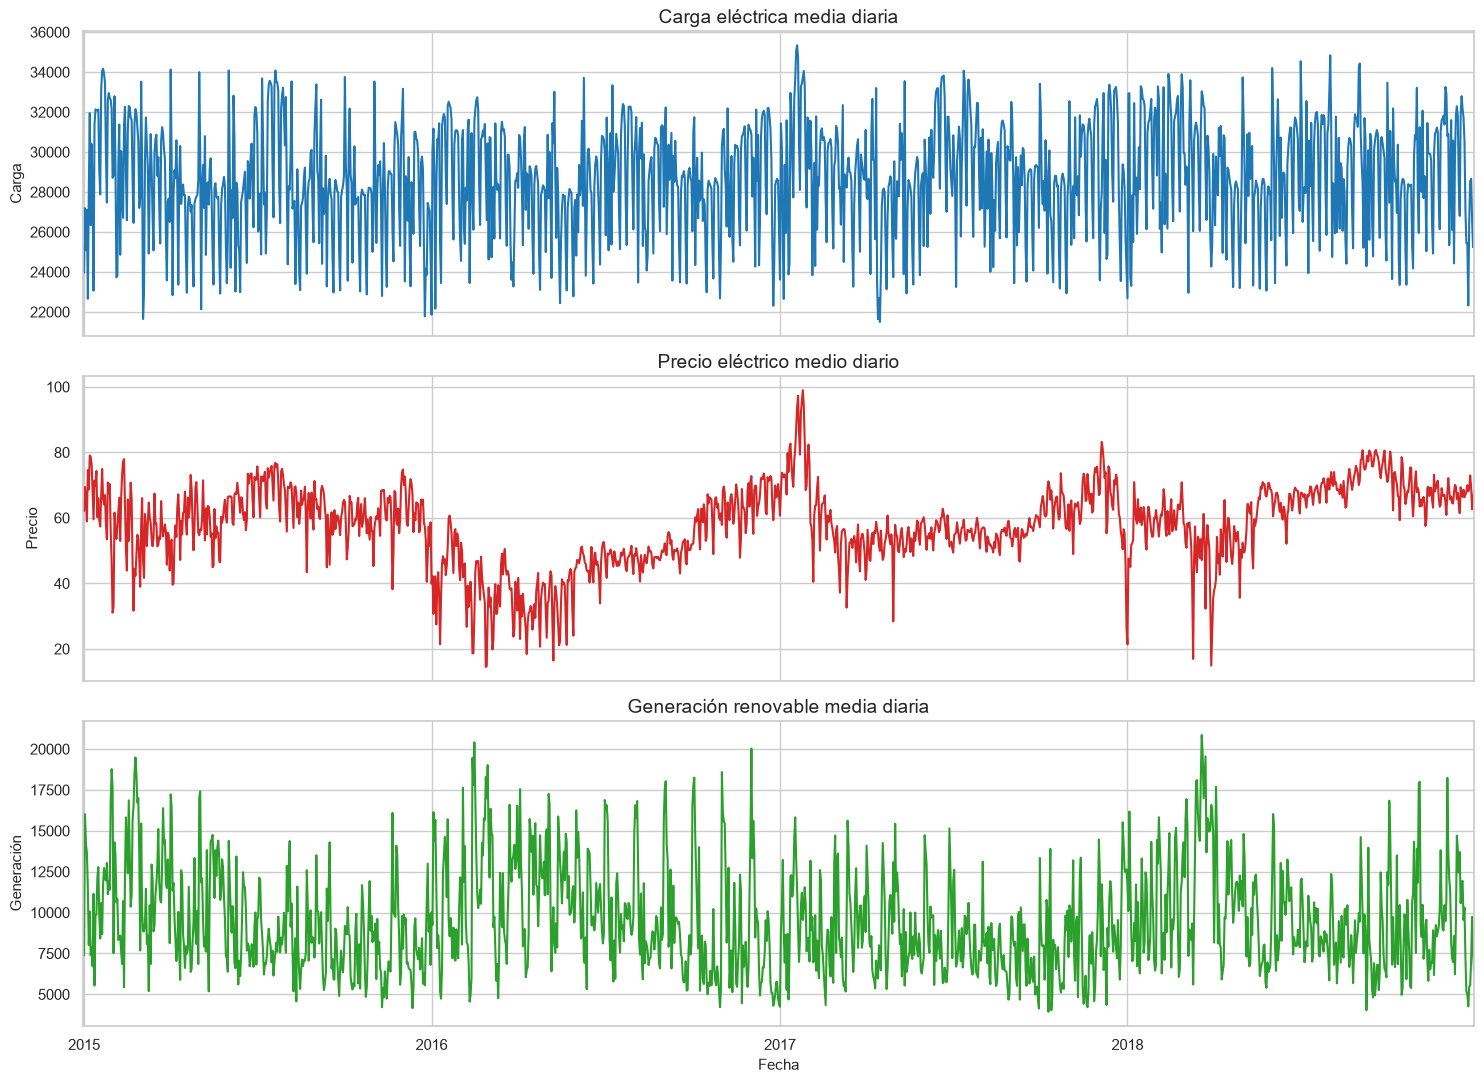

In [23]:
fig, axes = plt.subplots(
    3,
    1,
    figsize=(15, 11),
    sharex=True
)

daily["total load actual"].plot(
    ax=axes[0],
    color="tab:blue"
)
axes[0].set_title("Carga eléctrica media diaria")
axes[0].set_ylabel("Carga")

daily["price actual"].plot(
    ax=axes[1],
    color="tab:red"
)
axes[1].set_title("Precio eléctrico medio diario")
axes[1].set_ylabel("Precio")

daily["renewable_generation"].plot(
    ax=axes[2],
    color="tab:green"
)
axes[2].set_title("Generación renovable media diaria")
axes[2].set_ylabel("Generación")
axes[2].set_xlabel("Fecha")

plt.tight_layout()
plt.show()

### Observaciones

La carga eléctrica media diaria muestra una evolución relativamente
estable, con un aumento progresivo entre 2015 y 2018. La carga media
pasó de 28.362,44 en 2015 a 29.065,06 en 2018. El año 2014 se interpreta
con precaución porque contiene un periodo incompleto.

El precio eléctrico presenta una evolución más variable. El precio medio
disminuyó hasta alcanzar su valor mínimo en 2016, con 47,44, y aumentó
posteriormente hasta 63,44 en 2018. El diagrama de cajas muestra varios
valores extremos, especialmente en 2017 y 2018, lo que sugiere episodios
de volatilidad.

La generación renovable también presenta una variabilidad considerable.
Su media anual fue máxima en 2016, con 10.204,01, y mínima en 2014, con
8.326,00. No se observa una tendencia lineal constante durante todo el
periodo.

In [24]:
resumen_anual = (
    daily
    .groupby(daily.index.year)
    .agg({
        "total load actual": "mean",
        "price actual": "mean",
        "renewable_generation": "mean"
    })
    .round(2)
)

resumen_anual

,total load actual,price actual,renewable_generation
time,,,
2014,25385.00,65.41,8326.00
2015,28362.44,61.36,9469.32
2016,28507.85,47.44,10204.01
2017,28858.36,59.32,8479.90
2018,29065.06,63.44,9857.97


In [25]:
resumen_anual_completo = resumen_anual.loc[2015:2018]

resumen_anual_completo

,total load actual,price actual,renewable_generation
time,,,
2015,28362.44,61.36,9469.32
2016,28507.85,47.44,10204.01
2017,28858.36,59.32,8479.90
2018,29065.06,63.44,9857.97


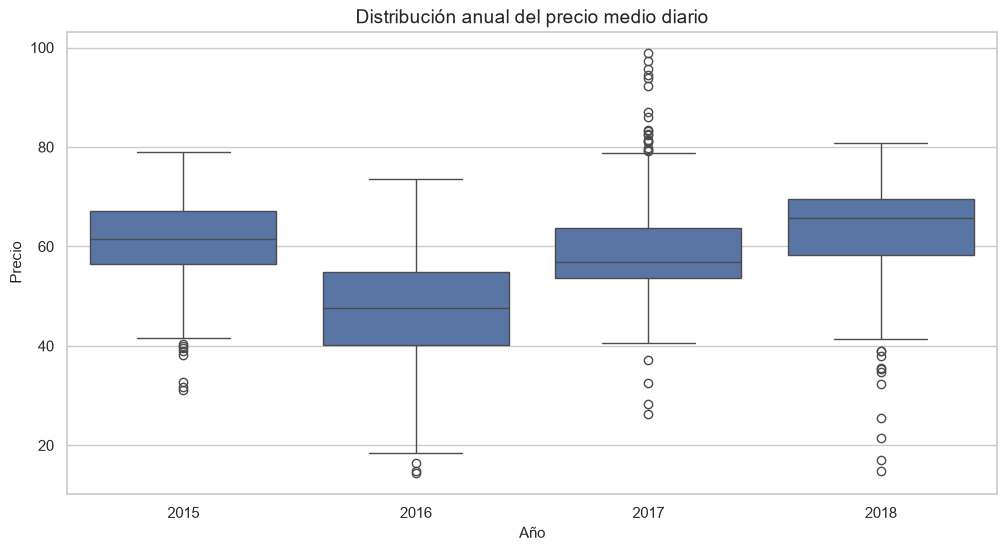

In [26]:
daily_completo = daily[daily.index.year >= 2015].copy()

daily_completo["year"] = daily_completo.index.year

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=daily_completo,
    x="year",
    y="price actual"
)

plt.title("Distribución anual del precio medio diario")
plt.xlabel("Año")
plt.ylabel("Precio")
plt.show()

### Interpretación del precio por año

El diagrama de cajas muestra diferencias claras entre los años completos
analizados. En 2016 se observa la mediana más baja, con un precio central
cercano a 47–48. En cambio, 2018 presenta la mediana más elevada, cercana
a 66.

El año 2017 destaca por la presencia de numerosos valores atípicos altos,
algunos próximos a 100, lo que sugiere episodios puntuales de elevada
volatilidad. En 2015 y 2018 también aparecen valores atípicos bajos,
aunque con menor concentración.

Los valores atípicos se mantienen en el análisis porque pueden representar
situaciones reales del mercado y no necesariamente errores de medición.

## 12. Perfil horario

In [27]:
perfil_horario = (
    energy
    .groupby("hour")["total load actual"]
    .agg(
        media="mean",
        mediana="median",
        desviacion="std"
    )
    .reset_index()
)

perfil_horario.round(2)

,hour,media,mediana,desviacion
0,0,23951.78,23837.0,1734.28
1,1,23148.22,23139.0,1590.10
2,2,22785.64,22836.0,1560.02
3,3,22849.86,22973.0,1606.18
4,4,23847.33,24098.0,2080.02
5,5,25805.53,26546.0,3076.52
6,6,28003.59,29265.0,3925.82
7,7,29800.58,30786.0,4195.72
8,8,31077.96,31502.0,3929.93
9,9,31806.05,31955.0,3672.74


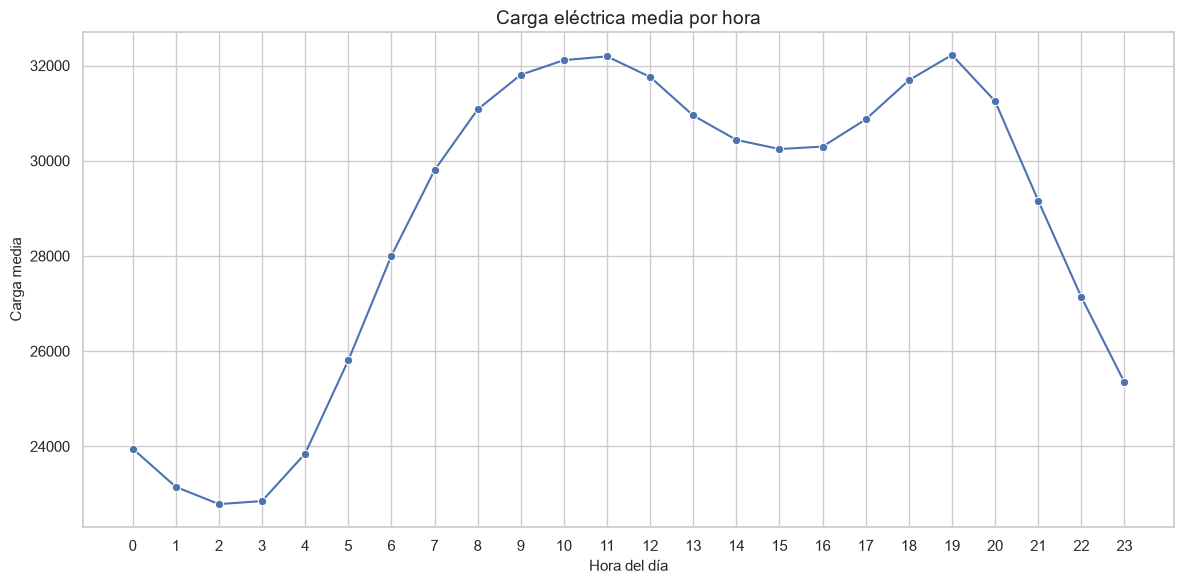

In [28]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=perfil_horario,
    x="hour",
    y="media",
    marker="o"
)

plt.title("Carga eléctrica media por hora")
plt.xlabel("Hora del día")
plt.ylabel("Carga media")
plt.xticks(range(24))
plt.tight_layout()
plt.show()

El nivel también es muy bajo entre las 1:00 y las 4:00. Esto representa el periodo nocturno de menor actividad.

Existe otro pico importante entre las 10:00 y las 12:00, especialmente a las 11:00, con una media de 32.192,97.

El patrón tiene, por tanto, dos zonas de alta demanda:

Un pico durante la mañana, aproximadamente entre las 10:00 y las 12:00.

Un pico durante la tarde-noche, alrededor de las 18:00–20:00.

In [29]:
hora_minima = perfil_horario.loc[
    perfil_horario["media"].idxmin()
]

hora_maxima = perfil_horario.loc[
    perfil_horario["media"].idxmax()
]

print("Hora de menor carga:")
display(hora_minima)

print("Hora de mayor carga:")
display(hora_maxima)

Hora de menor carga:


hour              2.000000
media         22785.642710
mediana       22836.000000
desviacion     1560.020891
Name: 2, dtype: float64

Hora de mayor carga:


hour             19.000000
media         32222.812799
mediana       32068.000000
desviacion     3128.377266
Name: 19, dtype: float64

In [30]:
amplitud_diaria = (
    hora_maxima["media"]
    - hora_minima["media"]
)

print(f"Amplitud diaria: {amplitud_diaria:.2f}")

Amplitud diaria: 9437.17


Esta diferencia muestra una variación importante entre las horas de menor y mayor demanda.

In [31]:
print(
    f"Mínimo: {hora_minima['hour']}:00 "
    f"con {hora_minima['media']:.2f}"
)

print(
    f"Máximo: {hora_maxima['hour']}:00 "
    f"con {hora_maxima['media']:.2f}"
)

Mínimo: 2.0:00 con 22785.64
Máximo: 19.0:00 con 32222.81


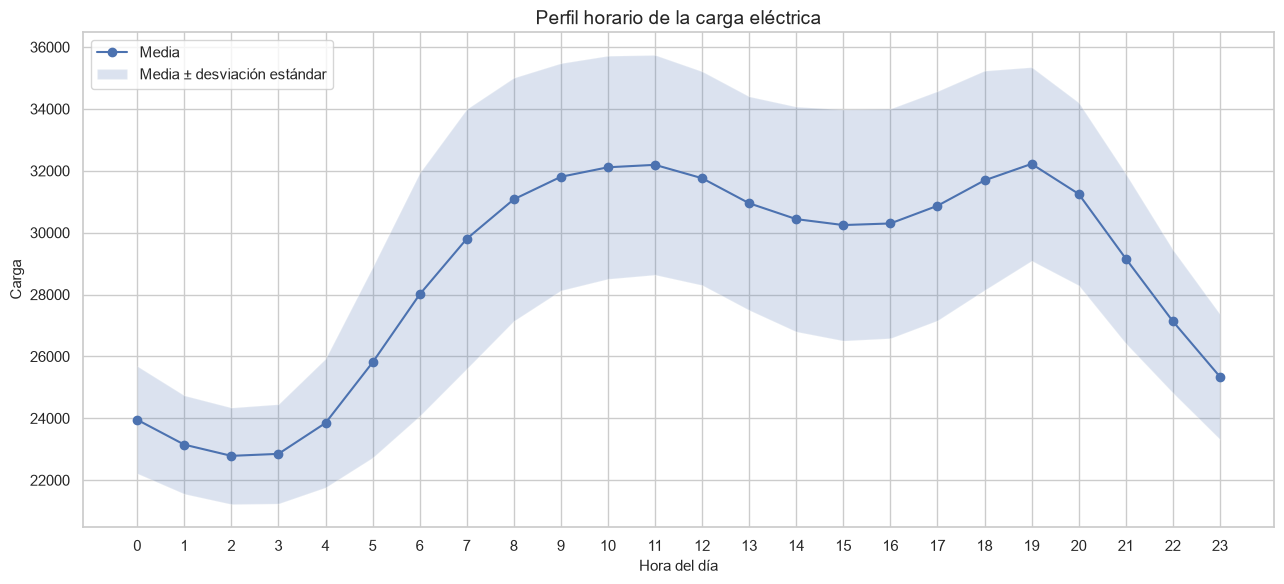

In [32]:
plt.figure(figsize=(13, 6))

plt.plot(
    perfil_horario["hour"],
    perfil_horario["media"],
    marker="o",
    label="Media"
)

plt.fill_between(
    perfil_horario["hour"],
    perfil_horario["media"] - perfil_horario["desviacion"],
    perfil_horario["media"] + perfil_horario["desviacion"],
    alpha=0.2,
    label="Media ± desviación estándar"
)

plt.title("Perfil horario de la carga eléctrica")
plt.xlabel("Hora del día")
plt.ylabel("Carga")
plt.xticks(range(24))
plt.legend()
plt.tight_layout()
plt.show()

La desviación estándar es más baja durante la madrugada:

2:00: aproximadamente 1.560.

3:00: aproximadamente 1.606.

4:00: aproximadamente 2.080.

Aumenta durante las horas de mayor actividad:

7:00: aproximadamente 4.195.

8:00: aproximadamente 3.930.

19:00: aproximadamente 3.128.

20:00: aproximadamente 2.954.

Esto significa que la carga no solo es mayor durante la mañana y la tarde, sino que también presenta mayor variabilidad entre los distintos días.

### Perfil horario

El análisis horario permite identificar el patrón diario de la carga
eléctrica. La demanda presenta sus niveles más bajos durante la
madrugada y aumenta durante la mañana.

La comparación entre la hora de menor y mayor carga permite cuantificar
la amplitud del patrón diario. La desviación estándar se utiliza para
observar si la variabilidad cambia según la hora.

Las horas se interpretan en UTC, por lo que un análisis basado en hábitos
de consumo local debería utilizar posteriormente la zona horaria
`Europe/Madrid`.

Carga eléctrica media por hora — Europe/Madrid

In [33]:
energy_local = energy.copy()

energy_local.index = energy_local.index.tz_convert(
    "Europe/Madrid"
)

energy_local["hour_madrid"] = energy_local.index.hour

perfil_madrid = (
    energy_local
    .groupby("hour_madrid")["total load actual"]
    .agg(
        media="mean",
        mediana="median",
        desviacion="std"
    )
    .reset_index()
)

hora_minima_madrid = perfil_madrid.loc[
    perfil_madrid["media"].idxmin()
]

hora_maxima_madrid = perfil_madrid.loc[
    perfil_madrid["media"].idxmax()
]

print(
    f"Mínimo: {hora_minima_madrid['hour_madrid']}:00 "
    f"con {hora_minima_madrid['media']:.2f}"
)

print(
    f"Máximo: {hora_maxima_madrid['hour_madrid']}:00 "
    f"con {hora_maxima_madrid['media']:.2f}"
)

Mínimo: 4.0:00 con 22709.10
Máximo: 13.0:00 con 32182.33


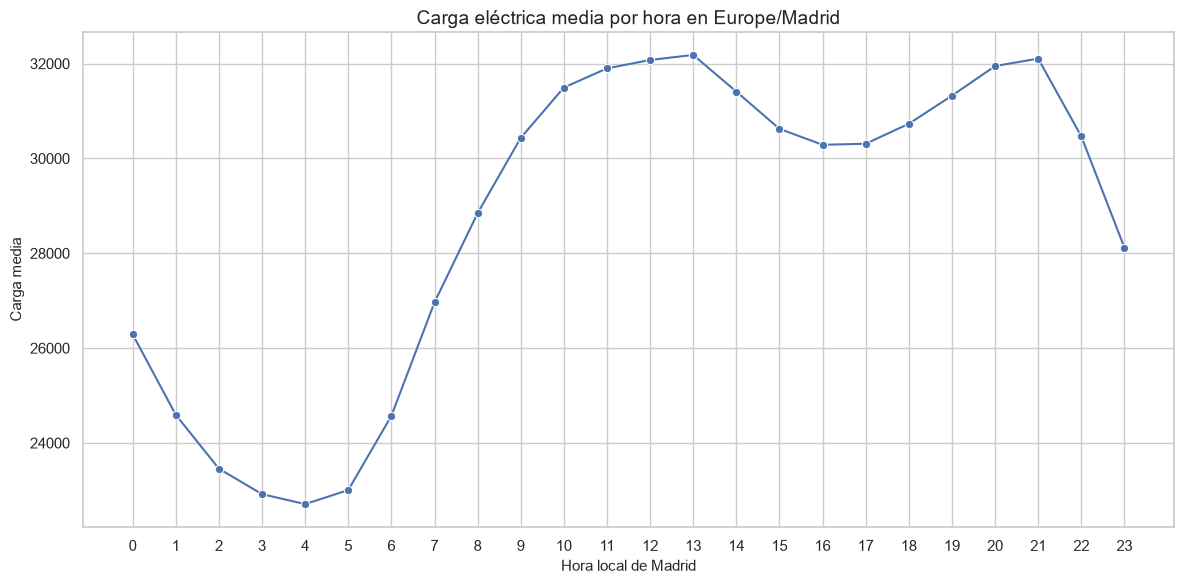

In [34]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=perfil_madrid,
    x="hour_madrid",
    y="media",
    marker="o"
)

plt.title("Carga eléctrica media por hora en Europe/Madrid")
plt.xlabel("Hora local de Madrid")
plt.ylabel("Carga media")
plt.xticks(range(24))
plt.tight_layout()
plt.show()

Menor carga aproximadamente a las 4:00, con unos 22.785,64.

Aumento claro desde las 6:00.

Primer periodo elevado entre las 10:00 y las 13:00.

Descenso moderado entre las 14:00 y las 17:00.

Segundo máximo alrededor de las 20:00–21:00.

Descenso fuerte desde las 22:00.

El máximo que aparece a las 19:00 en el gráfico anterior puede desplazarse a las 20:00 al convertir de UTC a Madrid, especialmente durante el horario de invierno. Esto es normal: Europe/Madrid alterna entre UTC+1 y UTC+2 según la época del año.

## 13. Laborables frente a fines de semana

In [35]:
perfil_tipo_dia = (
    energy
    .groupby(["day_type", "hour"])["total load actual"]
    .agg(
        media="mean",
        mediana="median",
        desviacion="std"
    )
    .reset_index()
)

perfil_tipo_dia.head()

,day_type,hour,media,mediana,desviacion
0,Fin de semana,0,23679.454545,23643.0,1758.664871
1,Fin de semana,1,22766.630383,22704.5,1579.491927
2,Fin de semana,2,22292.433014,22258.5,1533.856554
3,Fin de semana,3,22166.736842,22077.0,1567.092479
4,Fin de semana,4,22623.203349,22342.0,2012.740944


In [36]:
energy["day_type"].value_counts()

day_type
Laborable        25032
Fin de semana    10032
Name: count, dtype: int64

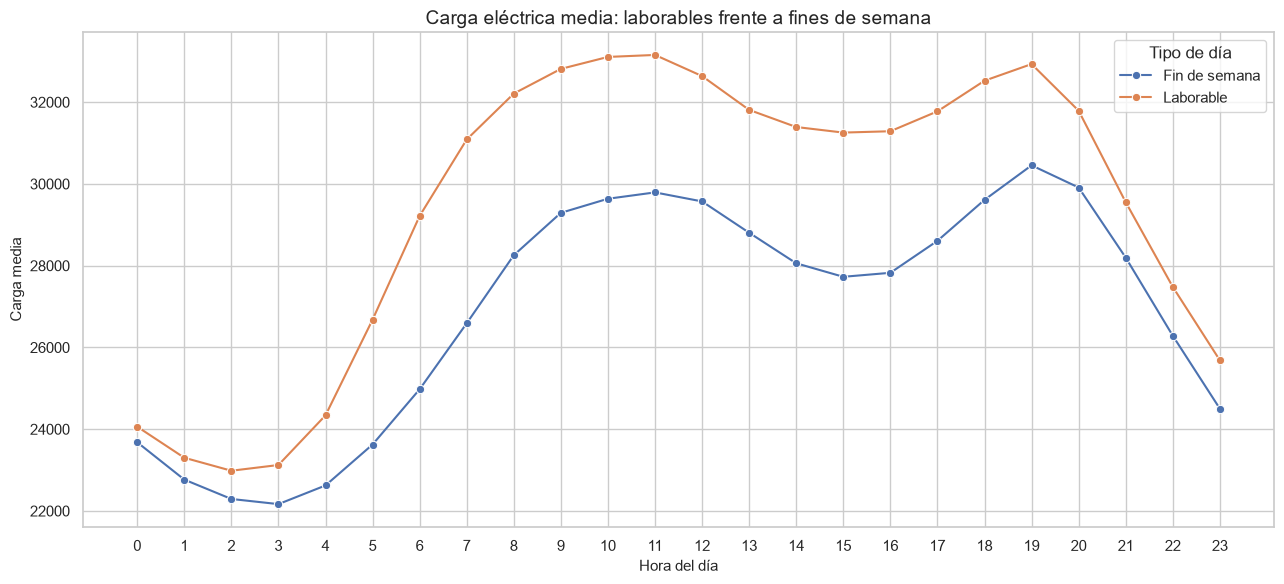

In [37]:
plt.figure(figsize=(13, 6))

sns.lineplot(
    data=perfil_tipo_dia,
    x="hour",
    y="media",
    hue="day_type",
    marker="o"
)

plt.title("Carga eléctrica media: laborables frente a fines de semana")
plt.xlabel("Hora del día")
plt.ylabel("Carga media")
plt.xticks(range(24))
plt.legend(title="Tipo de día")
plt.tight_layout()
plt.show()

### Versión para Europe/Madrid

In [38]:
perfil_tipo_dia_madrid = (
    energy_local
    .groupby(["day_type", "hour_madrid"])["total load actual"]
    .agg(
        media="mean",
        mediana="median",
        desviacion="std"
    )
    .reset_index()
)

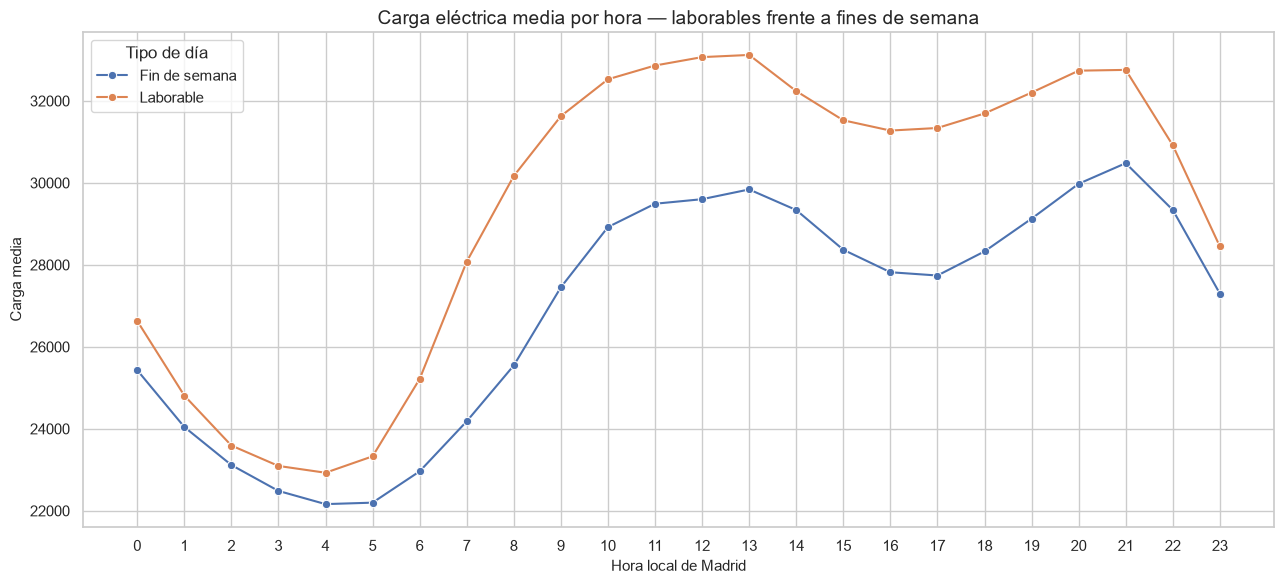

In [39]:
plt.figure(figsize=(13, 6))

sns.lineplot(
    data=perfil_tipo_dia_madrid,
    x="hour_madrid",
    y="media",
    hue="day_type",
    marker="o"
)

plt.title(
    "Carga eléctrica media por hora "
    "— laborables frente a fines de semana"
)
plt.xlabel("Hora local de Madrid")
plt.ylabel("Carga media")
plt.xticks(range(24))
plt.legend(title="Tipo de día")
plt.tight_layout()
plt.show()

El gráfico muestra que los días laborables presentan una carga superior prácticamente durante todo el día.

Días laborables
Mínimo: alrededor de las 4:00, con aproximadamente 22.983.

Primer máximo: alrededor de las 13:00, con aproximadamente 33.155.

Segundo máximo: alrededor de las 20:00–21:00, con valores próximos a 32.800–32.900.

Fines de semana
Mínimo: alrededor de las 3:00, con aproximadamente 22.167.

Máximo: alrededor de las 19:00, con aproximadamente 30.454.

La curva es más baja durante la mañana y la tarde.

In [40]:
comparacion_dias = (
    energy
    .groupby("day_type")["total load actual"]
    .agg(
        media="mean",
        mediana="median",
        desviacion="std",
        minimo="min",
        maximo="max"
    )
    .round(2)
)

comparacion_dias

,media,mediana,desviacion,minimo,maximo
day_type,,,,,
Fin de semana,26885.52,26565.5,4023.75,18380.0,40239.0
Laborable,29424.78,29961.5,4582.23,18041.0,41015.0


La desviación estándar es algo mayor en laborables:

Laborables:      4.582,23
Fin de semana:   4.023,75
Esto indica que la carga laboral presenta una variabilidad ligeramente superior. La actividad durante días de trabajo probablemente genera una demanda más elevada y más cambiante.

In [41]:
media_laborable = (
    energy.loc[
        energy["day_type"] == "Laborable",
        "total load actual"
    ].mean()
)

media_fin_semana = (
    energy.loc[
        energy["day_type"] == "Fin de semana",
        "total load actual"
    ].mean()
)

diferencia = media_laborable - media_fin_semana

print(f"Diferencia de medias: {diferencia:.2f}")

Diferencia de medias: 2539.25


In [42]:
hora_maxima_tipo = (
    perfil_tipo_dia
    .loc[
        perfil_tipo_dia
        .groupby("day_type")["media"]
        .idxmax()
    ]
)

hora_minima_tipo = (
    perfil_tipo_dia
    .loc[
        perfil_tipo_dia
        .groupby("day_type")["media"]
        .idxmin()
    ]
)

display(hora_maxima_tipo)
display(hora_minima_tipo)

,day_type,hour,media,mediana,desviacion
19,Fin de semana,19,30454.114833,30276.0,2692.206107
35,Laborable,11,33154.742090,33263.0,3168.452168


,day_type,hour,media,mediana,desviacion
3,Fin de semana,3,22166.736842,22077.0,1567.092479
26,Laborable,2,22983.304890,23025.0,1526.992369


### Interpretación

La carga eléctrica media es superior durante los días laborables. La
media de los días laborables es de 29.424,78, mientras que la media de
los fines de semana es de 26.885,52.

La diferencia absoluta entre ambos grupos es de 2.539,25 unidades, lo
que equivale aproximadamente a un 9,45 % respecto a la carga media de
los fines de semana.

El perfil horario muestra que la diferencia se mantiene durante la mayor
parte del día. En los días laborables se observa un primer máximo
alrededor de las 13:00 y un segundo periodo elevado alrededor de las
20:00–21:00. Durante los fines de semana, la carga máxima aparece
aproximadamente a las 19:00 y se mantiene por debajo de la observada en
días laborables.

La desviación estándar es ligeramente mayor en días laborables, lo que
indica una variabilidad algo superior. Las horas del análisis están
expresadas en hora local de Madrid.

## 14. Correlaciones

,total load actual,total load forecast,price actual,price day ahead,renewable_generation,load_forecast_error,price_forecast_error
total load actual,1.00,0.99,0.25,0.35,0.16,0.03,-0.15
total load forecast,0.99,1.00,0.25,0.35,0.16,-0.09,-0.15
price actual,0.25,0.25,1.00,0.72,-0.34,-0.01,0.32
price day ahead,0.35,0.35,0.72,1.00,-0.59,-0.00,-0.43
renewable_generation,0.16,0.16,-0.34,-0.59,1.00,0.00,0.36
load_forecast_error,0.03,-0.09,-0.01,-0.00,0.00,1.00,-0.01
price_forecast_error,-0.15,-0.15,0.32,-0.43,0.36,-0.01,1.00


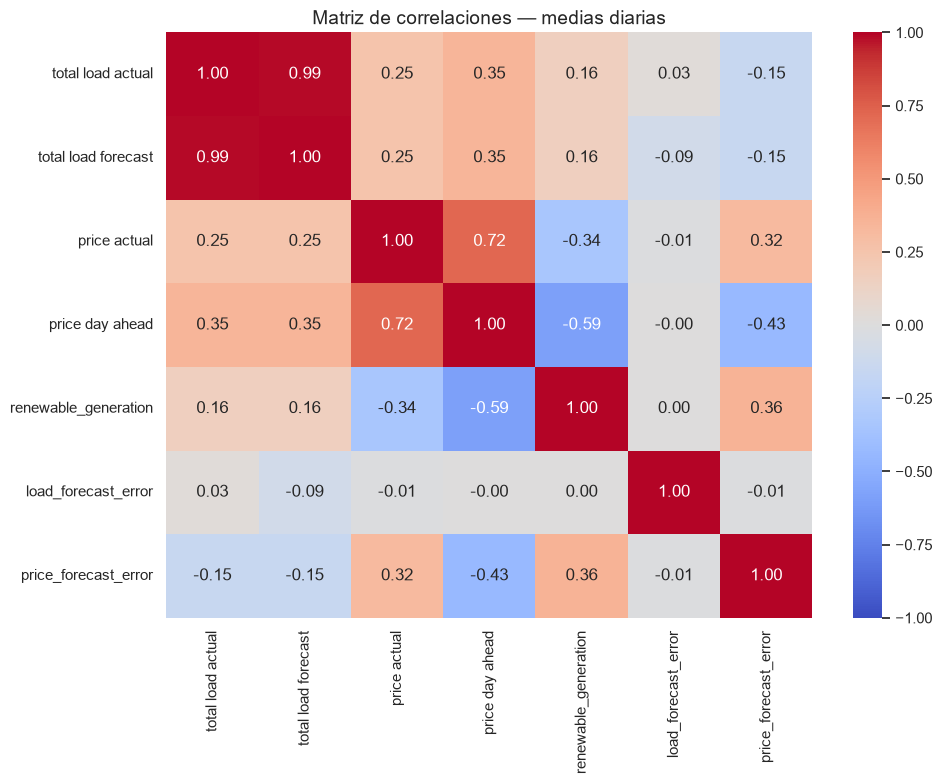

In [43]:
variables_correlacion = [
    "total load actual",
    "total load forecast",
    "price actual",
    "price day ahead",
    "renewable_generation",
    "load_forecast_error",
    "price_forecast_error"
]

matriz_corr = (
    daily[variables_correlacion]
    .corr()
    .round(2)
)

display(matriz_corr)

plt.figure(figsize=(10, 8))

sns.heatmap(
    matriz_corr,
    annot=True,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Matriz de correlaciones — medias diarias")
plt.tight_layout()
plt.show()


"Carga real y prevista": 0,99

Existe una relación lineal positiva casi perfecta entre:

total load actual,
total load forecast

Esto indica que la previsión sigue muy bien el comportamiento general de la carga. Sin embargo, una correlación alta no implica que los valores previstos sean idénticos; puede seguir existiendo un error considerable en determinadas horas.

"Precio real y previsto": 0,72

La correlación entre el precio real y el precio previsto es positiva y moderadamente alta:

La previsión captura parte importante del comportamiento del precio, pero con menos precisión que en el caso de la carga.

Esto es coherente con el análisis anterior, donde observaste un error absoluto medio del precio de aproximadamente 10,49 unidades.

"Generación renovable y precio previsto": -0,59
La relación negativa más fuerte aparece entre:

renewable_generation
price day ahead
con una correlación de:-0,59

En términos descriptivos, los días con mayor generación renovable tienden a asociarse con precios previstos más bajos. Esta relación no demuestra causalidad, pero es una señal relevante para investigar.

"Generación renovable y precio real": -0,34

La correlación con el precio real es negativa, pero más débil: -0,34
Esto puede indicar que la generación renovable se relaciona con precios más bajos, aunque el precio real también depende de otras variables, como demanda, generación convencional, costes y condiciones del mercad

### Interpretación de las correlaciones

La correlación entre la carga real y la carga prevista es de 0,99, lo que
indica una relación lineal positiva casi perfecta. La previsión reproduce
correctamente la evolución general de la demanda, aunque esta correlación
no implica que el error de previsión sea nulo.

La correlación entre el precio real y el precio previsto es de 0,72. La
relación es positiva y moderadamente alta, pero inferior a la observada
en la carga, lo que refleja una mayor dificultad para anticipar el precio
eléctrico.

La generación renovable presenta una relación negativa con el precio
previsto, de -0,59, y una relación negativa más débil con el precio real,
de -0,34. Descriptivamente, los días con mayor generación renovable
tienden a coincidir con precios más bajos, aunque la correlación no
demuestra causalidad.

La relación entre la carga real y el precio real es positiva pero débil,
con un valor de 0,25. Esto indica que la demanda por sí sola no explica
completamente la variación del precio.

## 15. Pearson y Spearman

In [45]:
relaciones = [
    ("total load actual", "total load forecast"),
    ("price actual", "price day ahead"),
    ("renewable_generation", "price actual")
]

In [46]:
resultados = []

for variable_x, variable_y in relaciones:
    datos = daily[[variable_x, variable_y]].dropna()

    pearson_r, pearson_p = stats.pearsonr(
        datos[variable_x],
        datos[variable_y]
    )

    spearman_r, spearman_p = stats.spearmanr(
        datos[variable_x],
        datos[variable_y]
    )

    resultados.append({
        "variable_x": variable_x,
        "variable_y": variable_y,
        "n": len(datos),
        "pearson_r": pearson_r,
        "pearson_p": pearson_p,
        "spearman_r": spearman_r,
        "spearman_p": spearman_p
    })

resultados_corr = pd.DataFrame(resultados).round(4)

resultados_corr

,variable_x,variable_y,n,pearson_r,pearson_p,spearman_r,spearman_p
0,total load actual,total load forecast,1462,0.9936,0.0,0.9925,0.0
1,price actual,price day ahead,1462,0.7183,0.0,0.7148,0.0
2,renewable_generation,price actual,1462,-0.3401,0.0,-0.3167,0.0


In [47]:
def interpretar_pvalor(p, alpha=0.05):
    if p < alpha:
        return "Asociación estadísticamente significativa"
    return "No hay evidencia suficiente de asociación"

resultados_corr["interpretacion_pearson"] = (
    resultados_corr["pearson_p"]
    .apply(interpretar_pvalor)
)

resultados_corr["interpretacion_spearman"] = (
    resultados_corr["spearman_p"]
    .apply(interpretar_pvalor)
)

resultados_corr

,variable_x,variable_y,n,pearson_r,pearson_p,spearman_r,spearman_p,interpretacion_pearson,interpretacion_spearman
0,total load actual,total load forecast,1462,0.9936,0.0,0.9925,0.0,Asociación estadísticamente significativa,Asociación estadísticamente significativa
1,price actual,price day ahead,1462,0.7183,0.0,0.7148,0.0,Asociación estadísticamente significativa,Asociación estadísticamente significativa
2,renewable_generation,price actual,1462,-0.3401,0.0,-0.3167,0.0,Asociación estadísticamente significativa,Asociación estadísticamente significativa


"Carga real y carga prevista"

Pearson:  0,9936
Spearman: 0,9925

Ambos coeficientes son casi idénticos y muy cercanos a 1. Esto indica una relación lineal muy fuerte y estable entre la carga real y la prevista.

La previsión reproduce muy bien la evolución diaria de la demanda. Sin embargo, debes distinguir entre:
Correlación: mide si ambas series suben y bajan juntas.

Error: mide cuánto se separan los valores.
Por tanto, una correlación de 0,9936 no significa que el error de previsión sea cero.

"Precio real y precio previsto"

Pearson:  0,7183
Spearman: 0,7148

La relación es positiva y moderadamente alta. Los dos coeficientes son muy parecidos, por lo que la relación parece principalmente lineal y no está dominada de forma extrema por valores atípicos.
La previsión del precio sigue parte importante de la dinámica real, aunque con una precisión inferior a la observada en la carga.

"Generación renovable y precio real"

Pearson:  -0,3401
Spearman: -0,3167

La relación es negativa y de intensidad débil a moderada. En los datos diarios, los días con mayor generación renovable tienden a asociarse con precios reales más bajos.
No obstante, la correlación no demuestra que la generación renovable sea la causa directa de la reducción del precio. También pueden influir la demanda, la generación convencional, la estación del año y otros factores del mercado.

In [48]:
resultados_corr["diferencia_coeficientes"] = (
    resultados_corr["pearson_r"]
    - resultados_corr["spearman_r"]
).round(4)

resultados_corr

,variable_x,variable_y,n,pearson_r,pearson_p,spearman_r,spearman_p,interpretacion_pearson,interpretacion_spearman,diferencia_coeficientes
0,total load actual,total load forecast,1462,0.9936,0.0,0.9925,0.0,Asociación estadísticamente significativa,Asociación estadísticamente significativa,0.0011
1,price actual,price day ahead,1462,0.7183,0.0,0.7148,0.0,Asociación estadísticamente significativa,Asociación estadísticamente significativa,0.0035
2,renewable_generation,price actual,1462,-0.3401,0.0,-0.3167,0.0,Asociación estadísticamente significativa,Asociación estadísticamente significativa,-0.0234


Carga real-prevista:             0,0011
Precio real-previsto:            0,0035
Renovable-precio real:          -0,0234
Esto significa que Pearson y Spearman producen resultados muy similares.

Para la tercera relación, la diferencia es algo mayor, pero sigue siendo pequeña. Por tanto, la relación negativa entre generación renovable y precio no parece depender exclusivamente de unos pocos valores extremos.

### Interpretación de Pearson y Spearman

Las tres relaciones analizadas presentan p-valores inferiores a 0,05,
por lo que existe evidencia estadística de asociación en los datos
diarios.

La relación entre la carga real y la prevista es muy fuerte, con una
correlación de Pearson de 0,9936 y de Spearman de 0,9925. Esto indica que
la previsión reproduce correctamente la evolución diaria de la demanda.

La relación entre el precio real y el precio previsto es positiva y
moderadamente alta, con valores de 0,7183 para Pearson y 0,7148 para
Spearman. La previsión del precio sigue la dinámica general del precio
real, aunque con menor precisión que la previsión de carga.

La generación renovable presenta una relación negativa con el precio
real, con una correlación de Pearson de -0,3401 y de Spearman de -0,3167.
En términos descriptivos, una mayor generación renovable se asocia con
precios reales más bajos. Sin embargo, esta relación no demuestra
causalidad.

Las diferencias reducidas entre Pearson y Spearman sugieren que las
relaciones son aproximadamente lineales y no dependen excesivamente de
valores extremos.

## 16. Descomposición de la serie temporal

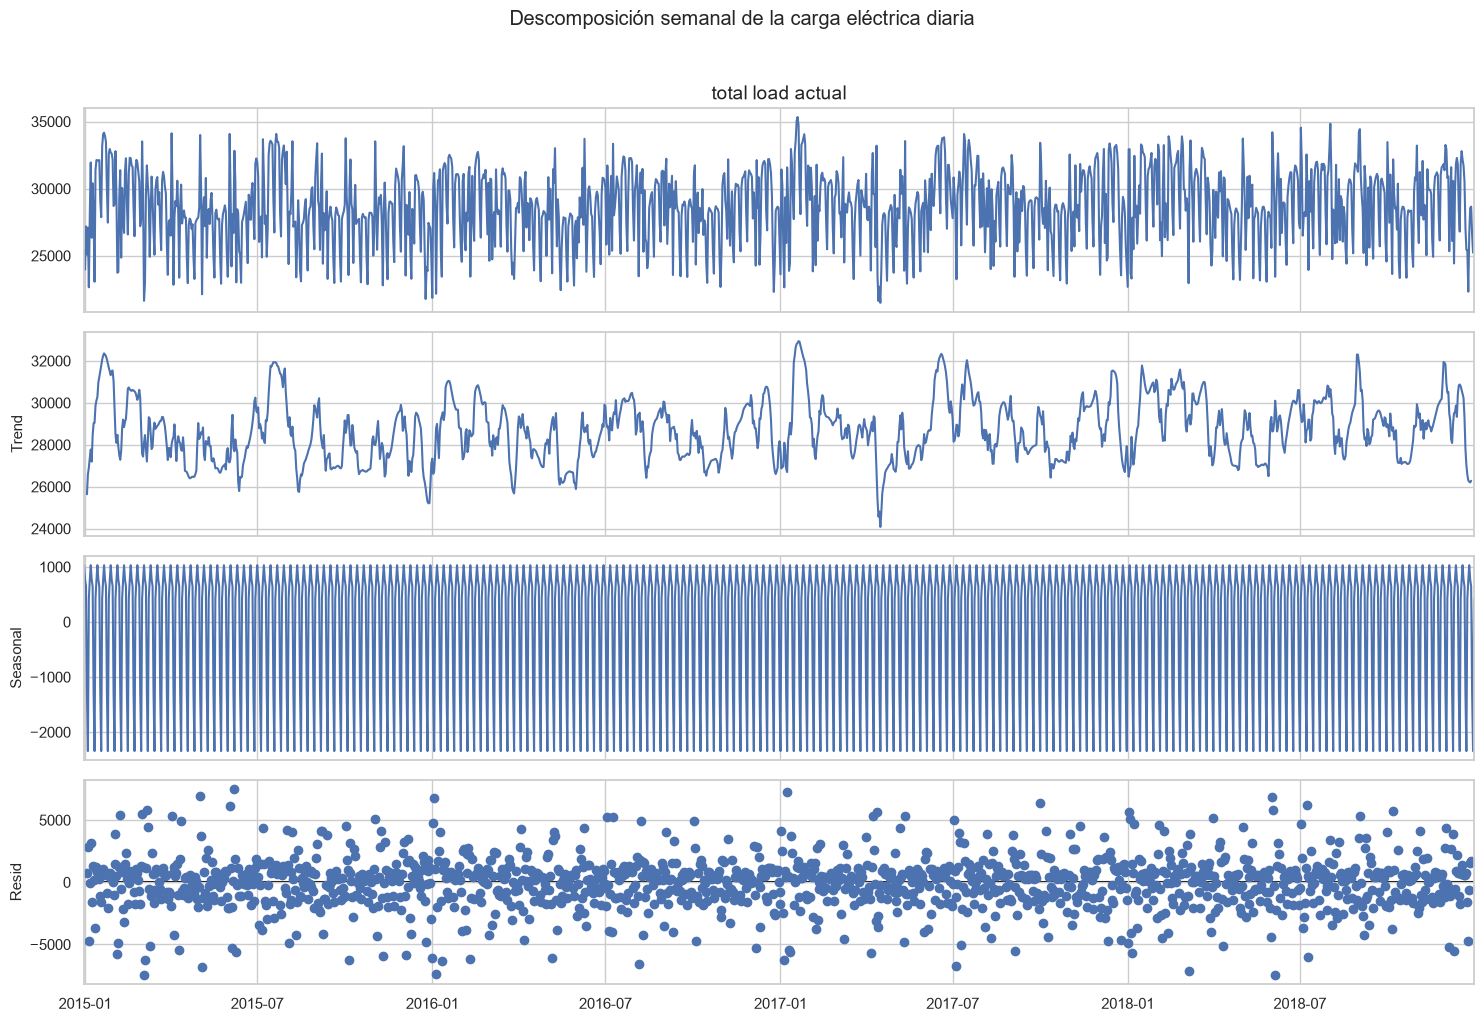

In [52]:
serie_carga_diaria = (
    daily["total load actual"]
    .asfreq("D")
    .interpolate(method="time")
)

descomposicion = seasonal_decompose(
    serie_carga_diaria,
    model="additive",
    period=7
)

fig = descomposicion.plot()
fig.set_size_inches(15, 10)
fig.suptitle(
    "Descomposición semanal de la carga eléctrica diaria",
    y=1.02
)

plt.tight_layout()
plt.show()

Serie observada

La "primera gráfica" representa la carga diaria original. Se observan variaciones frecuentes entre aproximadamente 22.000 y 35.000 unidades, con algunos picos y descensos puntuales.

La serie tiene bastante ruido diario, por lo que es difícil identificar directamente una tendencia solo observando esta primera parte.

Tendencia

La "segunda gráfica" suaviza parcialmente la serie y muestra una evolución variable, sin una tendencia lineal constante.

Se observan:
Periodos de aumento.
Periodos de descenso.
Oscilaciones alrededor de niveles distintos.
Algunos cambios de nivel temporales.

Por tanto, no parece existir un crecimiento continuo de la carga durante todo el periodo. Esto coincide con el análisis anual: la carga aumentó gradualmente entre 2015 y 2018, pero dentro de cada año presenta variaciones importantes.

Estacionalidad semanal

La "tercera gráfica" presenta un patrón repetitivo con periodo 7. La forma regular de la componente confirma que existe una estacionalidad semanal.
Los valores positivos y negativos indican que algunos días presentan una carga superior o inferior a la tendencia estimada. Este patrón es coherente con la diferencia observada entre:
Días laborables.
Fines de semana.

La estacionalidad semanal parece tener una amplitud aproximada de entre 2.000 y 2.500 unidades

In [55]:
residuos_validos = descomposicion.resid.dropna()

print("Media de residuos:", residuos_validos.mean())
print("Desviación estándar:", residuos_validos.std())
print("Residuos nulos:", descomposicion.resid.isna().sum())

Media de residuos: 1.0535421003703411
Desviación estándar: 2004.3782289743096
Residuos nulos: 6



La media es: 10.5
La media de los residuos es prácticamente cero, lo que indica que la descomposición no subestima ni sobreestima sistemáticamente la carga diaria.

La desviación estándar es:2.004,38

Esto indica que, aunque el residuo medio sea cercano a cero, todavía existe una variabilidad diaria considerable que no queda explicada por la tendencia y la estacionalidad semana

Residuos

La cuarta gráfica representa los residuos. La mayoría de los puntos se concentra alrededor de cero, pero también aparecen valores extremos positivos y negativos.

Esto significa que:
La descomposición captura una parte importante del patrón semanal.
Todavía existen variaciones diarias que no explican la tendencia y la estacionalidad.
Hay algunos días con comportamientos excepcionales.
Los residuos no parecen mostrar una dispersión completamente constante, porque algunos periodos presentan más valores extremos que otros. Conviene mencionarlo como una observación, no como una conclusión definitiva.

## 17. Prueba ADF

In [57]:
serie_adf = (
    daily["total load actual"]
    .dropna()
)

In [67]:
resultado_adf = adfuller(serie_adf)

estadistico_adf = resultado_adf[0]
p_valor_adf = resultado_adf[1]
lags_usados = resultado_adf[2]
observaciones = resultado_adf[3]
valores_criticos = resultado_adf[4]

print(f"Estadístico ADF: {estadistico_adf:.4f}")
print(f"p-valor: {p_valor_adf:.3e}")
print("Lags Utilizado:", lags_usados)
print("observaciones:", observaciones)

print("\nValores criticos:")
for nivel, valor in valores_criticos.items():
    print(f"{nivel}: {valor}")

Estadístico ADF: -6.4635
p-valor: 1.424e-08
Lags Utilizado: 21
observaciones: 1440

Valores criticos:
1%: -3.434899302257815
5%: -2.8635492080466607
10%: -2.567839687982253


El p-valor es muy inferior a 0,05:

Por tanto, se rechaza la hipótesis nula de existencia de raíz unitaria. Además, el estadístico ADF es más negativo que todos los valores críticos:

-6,4635 < -2,8635
Por ambas razones, hay evidencia estadística de que la serie diaria de carga es estacionaria.

In [62]:
alpha = 0.05

if p_valor_adf < alpha:
    print(
        "Conclusion: se rechaza H0."
        "La serie parece estacionaria."
    )
else:
    print(
        "Conclusion: no se rechaza H0."
        "La serie no parece estacionaria."
    )

Conclusion: se rechaza H0.La serie parece estacionaria.


In [63]:
print(
    "¿ADF menor que el valor critico al 5%?:",
    estadistico_adf < valores_criticos["5%"]
)

¿ADF menor que el valor critico al 5%?: True


In [66]:
serie_diferenciada = serie_adf.diff().dropna()

resultado_adf_diff = adfuller(serie_diferenciada)

print("ADF serie diferenciada:")
print("Estadistico:", resultado_adf_diff[0])
print("p-valor:", resultado_adf_diff[1])

ADF serie diferenciada:
Estadistico: -14.875286465421667
p-valor: 1.6400723638625775e-27


La primera diferencia también resulta estacionaria:

Estadístico ADF: -14,8753
p-valor: 1,64 × 10⁻²⁷

La serie diaria no presenta evidencia de raíz unitaria según la prueba ADF, aunque mantiene una estacionalidad semanal identificada mediante la descomposición.

In [65]:
if resultado_adf_diff[1]< 0.05:
    print("La primera diferencia aparece estacionaria.")
else:
    print("La primera diferencias no aperece estacionaria")

La primera diferencia aparece estacionaria.


### Resultado de la prueba ADF

La prueba ADF aplicada a la carga eléctrica diaria produjo un estadístico
de -6,4635 y un p-valor de 1,42 × 10⁻⁸.

Como el p-valor es inferior a 0,05, se rechaza la hipótesis nula de
existencia de una raíz unitaria. Además, el estadístico ADF es más
negativo que el valor crítico del 5 %, situado en -2,8635.

Por tanto, la serie diaria de carga parece estacionaria según la prueba
ADF. La primera diferencia también resultó estacionaria, aunque no es
necesaria para la conclusión principal porque la serie original ya
supera la prueba.

La estacionariedad según ADF no elimina la presencia de estacionalidad
semanal. La descomposición anterior mostró que la serie mantiene un
patrón repetitivo de siete días.

## 18. Hallazgos principales

### Comportamiento de la carga

La carga eléctrica presenta un patrón diario claramente definido. El
mínimo se observa durante la madrugada, mientras que la demanda aumenta
durante la mañana y vuelve a alcanzar niveles elevados durante la
tarde-noche.

En hora local de Madrid, la carga media es inferior durante los fines de
semana. La carga media de los días laborables fue de 29.424,78, frente a
26.885,52 durante los fines de semana. La diferencia fue de 2.539,25
unidades, aproximadamente un 9,45 %.

### Evolución anual

La carga media aumentó progresivamente entre 2015 y 2018, desde 28.362,44
hasta 29.065,06. El año 2014 se interpretó con precaución porque el
periodo disponible no representa un año completo.

### Comportamiento de los precios

El precio eléctrico presentó más variabilidad que la carga. El precio
medio fue más bajo en 2016, con 47,44, y aumentó posteriormente hasta
63,44 en 2018.

El diagrama de cajas mostró valores atípicos, especialmente en 2017 y
2018. Estos valores se conservaron porque pueden representar episodios
reales de volatilidad del mercado eléctrico.

### Generación renovable

La generación renovable presentó una variabilidad considerable. Su media
anual más alta se observó en 2016, con 10.204,01.

La correlación entre generación renovable y precio real fue negativa:
-0,3401 según Pearson y -0,3167 según Spearman. Esto indica que una
mayor generación renovable tiende a asociarse con precios reales más
bajos en los datos analizados. Sin embargo, esta asociación no demuestra
causalidad.

### Calidad de las previsiones

La carga real y la carga prevista mostraron una correlación muy fuerte:
0,9936 según Pearson y 0,9925 según Spearman.

El precio real y el precio previsto presentaron una correlación positiva
moderadamente alta: 0,7183 según Pearson y 0,7148 según Spearman.

La previsión del precio mostró un error medio positivo de 8,01 y un error
absoluto medio de aproximadamente 10,49 unidades. Esto indica que el
precio real fue, en promedio, superior al precio previsto.

### Estacionariedad y estacionalidad

La descomposición mostró una estacionalidad semanal coherente con la
diferencia entre días laborables y fines de semana. La media de los
residuos fue cercana a cero, con un valor de 1,05.

La prueba ADF produjo un estadístico de -6,4635 y un p-valor de
1,42 × 10⁻⁸. Por tanto, se rechazó la hipótesis nula de raíz unitaria y
la serie diaria de carga se consideró estacionaria según esta prueba.

In [68]:
hallazgos = pd.DataFrame({
    "Aspecto": [
        "Carga laborable",
        "Carga fin de semana",
        "Diferencia de carga",
        "Correlación carga real-prevista",
        "Correlación precio real-previsto",
        "Correlación renovable-precio real",
        "Error absoluto medio del precio",
        "Media de residuos",
        "p-valor ADF"
    ],
    "Resultado": [
        f"{media_laborable:.2f}",
        f"{media_fin_semana:.2f}",
        f"{diferencia:.2f}",
        "0.9936",
        "0.7183",
        "-0.3401",
        "10.49",
        "1.05",
        "1.42e-08"
    ]
})

hallazgos

,Aspecto,Resultado
0,Carga laborable,29424.78
1,Carga fin de semana,26885.52
2,Diferencia de carga,2539.25
3,Correlación carga real-prevista,0.9936
4,Correlación precio real-previsto,0.7183
5,Correlación renovable-precio real,-0.3401
6,Error absoluto medio del precio,10.49
7,Media de residuos,1.05
8,p-valor ADF,1.42e-08


## 19. Limitaciones resumidas

El dataset contiene algunos valores ausentes que fueron imputados
mediante interpolación temporal. El año 2014 es un periodo incompleto y
por ello no se compara directamente con los años completos.

Las horas se interpretaron en `Europe/Madrid`, aunque los datos originales
están expresados en UTC. Además, la agregación diaria puede ocultar
variaciones intradía, especialmente en los precios.

Las correlaciones muestran asociaciones, pero no implican causalidad. No
se incorporaron todas las variables meteorológicas ni todas las fuentes
de generación. Finalmente, el análisis es descriptivo y estadístico; no
incluye un modelo predictivo validado.

## 20. Conclusión

Este proyecto permitió analizar la evolución de la carga eléctrica, los
precios y la generación renovable mediante técnicas de análisis
exploratorio, estadística descriptiva y análisis de series temporales.

La carga eléctrica presentó un patrón diario claro. Los niveles más bajos
se observaron durante la madrugada y los valores más elevados durante la
mañana y la tarde-noche. Además, la carga media fue superior durante los
días laborables que durante los fines de semana. La diferencia entre
ambos grupos fue de 2.539,25 unidades, aproximadamente un 9,45 %.

El precio eléctrico mostró una variabilidad superior a la carga. El precio
medio fue más bajo en 2016 y aumentó posteriormente hasta 2018. También
se observaron valores extremos, especialmente en 2017 y 2018, que se
mantuvieron porque pueden representar episodios reales de volatilidad del
mercado.

La carga real y la carga prevista presentaron una relación muy fuerte, con
una correlación de Pearson de 0,9936. La relación entre el precio real y
el precio previsto fue positiva y moderadamente alta, con una correlación
de 0,7183. Esto indica que las previsiones siguen razonablemente la
evolución general de las variables, aunque la previsión de carga es más
precisa que la previsión de precio.

La generación renovable presentó una asociación negativa con el precio
real. La correlación de Pearson fue de -0,3401 y la de Spearman de
-0,3167. Esta relación sugiere que los días con mayor generación
renovable tienden a coincidir con precios más bajos, aunque el análisis
no permite establecer causalidad.

La descomposición mostró una estacionalidad semanal coherente con la
diferencia entre días laborables y fines de semana. La prueba ADF produjo
un estadístico de -6,4635 y un p-valor de 1,42 × 10⁻⁸, por lo que se
rechazó la hipótesis nula de raíz unitaria. En consecuencia, la serie
diaria de carga parece estacionaria según esta prueba.

En conjunto, el análisis muestra que la demanda eléctrica presenta
patrones temporales claros, mientras que los precios son más variables y
están asociados con múltiples factores. Los resultados proporcionan una
base para futuros análisis predictivos que incorporen variables
meteorológicas, todas las fuentes de generación y modelos específicos de
series temporales.